In [ ]:
import warnings
warnings.filterwarnings('ignore')
# !pip install -q numpy==1.26.4 pandas==2.2.2 scikit-learn==1.5.0 matplotlib seaborn
# !pip install -q tenseal
# !pip install -q concrete-ml

In [ ]:
import os
import time
import requests
import numpy as np
import pandas as pd
import scipy.io
import matplotlib.pyplot as plt
import seaborn as sns
import tenseal as ts

from scipy.stats import kurtosis, skew, pearsonr
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from concrete.ml.sklearn import LogisticRegression as ConcreteLogisticRegression

RNG_SEED = 42
np.random.seed(RNG_SEED)

USE_DRIVE = False
SAVE_DIR = "./FHE_Figures"
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    SAVE_DIR = "/content/drive/MyDrive/FHE_Figures"
os.makedirs(SAVE_DIR, exist_ok=True)
print(f"Saved: {SAVE_DIR}")


Figürler şuraya kaydedilecek: ./FHE_Figures


In [ ]:
def sigmoid_deg1(x):
    return 0.5 + 0.25 * x


def make_ckks_context(poly_modulus_degree=8192, coeff_mod_bit_sizes=(60, 40, 40, 60), scale_bits=40):
    context = ts.context(
        ts.SCHEME_TYPE.CKKS,
        poly_modulus_degree=poly_modulus_degree,
        coeff_mod_bit_sizes=list(coeff_mod_bit_sizes),
    )
    context.global_scale = 2 ** scale_bits
    context.generate_galois_keys()
    return context


def fhe_predict_single(context, x_row, w, b):
    enc_x = ts.ckks_vector(context, x_row.tolist())
    dot = enc_x.dot(w)
    return sigmoid_deg1(dot + b).decrypt()[0]


def fhe_predict_packed(context, X_batch, w, b):
    dot = None
    for i in range(X_batch.shape[1]):
        col = ts.ckks_vector(context, X_batch[:, i].tolist())
        dot = col * w[i] if dot is None else dot + col * w[i]
    return sigmoid_deg1(dot + b).decrypt()


def fhe_predict_batched(context, X, w, b, batch_size=100):
    preds = []
    start = time.perf_counter()
    for i in range(0, len(X), batch_size):
        batch = X[i:i + batch_size]
        decrypted = fhe_predict_packed(context, batch, w, b)
        preds.extend([1 if v > 0.5 else 0 for v in decrypted])
    return preds, time.perf_counter() - start


def fhe_predict_vectorized_batch(context, X_batch, w, b):
    X_batch = np.array(X_batch)
    features = X_batch.T
    vecs = [ts.ckks_vector(context, feat.tolist()) for feat in features]
    dot = vecs[0] * w[0]
    for i in range(1, len(vecs)):
        dot += vecs[i] * w[i]
    out = sigmoid_deg1(dot + b).decrypt()
    return [1 if v > 0.5 else 0 for v in out]


def fhe_predict_vectorized(context, X, w, b, batch_size=100):
    preds = []
    start = time.perf_counter()
    for i in range(0, len(X), batch_size):
        preds.extend(fhe_predict_vectorized_batch(context, X[i:i + batch_size], w, b))
    return preds, time.perf_counter() - start


def run_all_inference_modes(context, clf, concrete_model, X_test, y_test, w, b, batch_size=100):
    res = {}

    def record(name, y_pred, elapsed, y_score=None):
        entry = {
            "acc": accuracy_score(y_test, y_pred),
            "time": elapsed,
            "precision": precision_score(y_test, y_pred, zero_division=0),
            "recall": recall_score(y_test, y_pred, zero_division=0),
            "f1": f1_score(y_test, y_pred, zero_division=0),
        }
        if y_score is not None:
            try:
                entry["auc"] = roc_auc_score(y_test, y_score)
            except ValueError:
                entry["auc"] = float("nan")
        res[name] = entry

    t0 = time.perf_counter()
    y_pred_plain = clf.predict(X_test)
    plain_scores = clf.predict_proba(X_test)[:, 1]
    record("Plain", y_pred_plain, time.perf_counter() - t0, plain_scores)

    t0 = time.perf_counter()
    y_pred_single = [1 if fhe_predict_single(context, x, w, b) > 0.5 else 0 for x in X_test]
    record("CKKS-Single", y_pred_single, time.perf_counter() - t0)

    t0 = time.perf_counter()
    y_pred_packed = []
    for i in range(0, len(X_test), batch_size):
        decrypted = fhe_predict_packed(context, X_test[i:i + batch_size], w, b)
        y_pred_packed.extend([1 if v > 0.5 else 0 for v in decrypted])
    record("CKKS-Packed", y_pred_packed, time.perf_counter() - t0)

    y_pred_batched, t_batched = fhe_predict_batched(context, X_test, w, b, batch_size)
    record("CKKS-Batched", y_pred_batched, t_batched)

    y_pred_vec, t_vec = fhe_predict_vectorized(context, X_test, w, b, batch_size)
    record("CKKS-Vectorized", y_pred_vec, t_vec)

    t0 = time.perf_counter()
    y_pred_tfhe = concrete_model.predict(X_test)
    record("TFHE-ConcreteML", y_pred_tfhe, time.perf_counter() - t0)

    return res, {
        "Plain": y_pred_plain, "CKKS-Single": y_pred_single, "CKKS-Packed": y_pred_packed,
        "CKKS-Batched": y_pred_batched, "CKKS-Vectorized": y_pred_vec, "TFHE-ConcreteML": y_pred_tfhe,
    }


def summarize_results(res):
    plain_acc = res["Plain"]["acc"]
    rows = []
    for name, v in res.items():
        rows.append({
            "Mod": name,
            "Dogruluk (%)": round(v["acc"] * 100, 2),
            "Sure (s)": round(v["time"], 4),
            "Precision": round(v["precision"], 4),
            "Recall": round(v["recall"], 4),
            "F1": round(v["f1"], 4),
            "AUC": round(v.get("auc", float('nan')), 4) if not np.isnan(v.get("auc", float('nan'))) else None,
        })
    return pd.DataFrame(rows)


def decision_agreement_report(predictions_dict, reference_name="Plain"):
    reference = predictions_dict[reference_name]
    rows = []
    for name, preds in predictions_dict.items():
        if name == reference_name:
            continue
        n = min(len(reference), len(preds))
        agree = sum(1 for i in range(n) if reference[i] == preds[i])
        rows.append({"Karsilastirma": f"{reference_name} vs {name}", "Uyum (%)": round(agree / n * 100, 2),
                     "Uyumsuz Adet": n - agree})
    return pd.DataFrame(rows)


## Case Study I: AI4I 2020 Predictive Maintenance Dataset

In [5]:
AI4I_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00601/ai4i2020.csv"
df_ai4i = pd.read_csv(AI4I_URL)

df_ai4i['Type'] = df_ai4i['Type'].map({'L': 0, 'M': 1, 'H': 2})

feature_cols_ai4i = ['Type', 'Air temperature [K]', 'Process temperature [K]',
                     'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
X_ai4i = df_ai4i[feature_cols_ai4i].values.astype(float)
y_ai4i = df_ai4i['Machine failure'].values

print(f"Ariza orani: {y_ai4i.mean()*100:.1f}%  ({y_ai4i.sum()} / {len(y_ai4i)})")

scaler_ai4i = StandardScaler()
X_ai4i_scaled = scaler_ai4i.fit_transform(X_ai4i)

X_train_ai4i, X_test_ai4i, y_train_ai4i, y_test_ai4i = train_test_split(
    X_ai4i_scaled, y_ai4i, test_size=0.2, random_state=RNG_SEED, stratify=y_ai4i
)
print(f"Egitim: {X_train_ai4i.shape}, Test: {X_test_ai4i.shape}")


Ariza orani: 3.4%  (339 / 10000)
Egitim: (8000, 6), Test: (2000, 6)


In [ ]:
clf_ai4i = LogisticRegression(max_iter=1000, class_weight='balanced')
clf_ai4i.fit(X_train_ai4i, y_train_ai4i)
w_ai4i, b_ai4i = clf_ai4i.coef_[0], clf_ai4i.intercept_[0]

concrete_ai4i = ConcreteLogisticRegression(n_bits=8, class_weight='balanced')
concrete_ai4i.fit(X_train_ai4i, y_train_ai4i)

_ = concrete_ai4i.compile(X_train_ai4i)

ctx_ai4i = make_ckks_context()
print("AI4I modeli ve CKKS baglami hazir.")


AI4I modeli ve CKKS baglami hazir.


In [7]:
res_ai4i, preds_ai4i = run_all_inference_modes(
    ctx_ai4i, clf_ai4i, concrete_ai4i, X_test_ai4i, y_test_ai4i, w_ai4i, b_ai4i, batch_size=100
)
df_res_ai4i = summarize_results(res_ai4i)
print(df_res_ai4i.to_string(index=False))


            Mod  Dogruluk (%)  Sure (s)  Precision  Recall     F1    AUC
          Plain         82.05    0.0014     0.1390  0.8235 0.2378 0.9082
    CKKS-Single         82.05   25.1398     0.1390  0.8235 0.2378    NaN
    CKKS-Packed         82.05    0.6497     0.1390  0.8235 0.2378    NaN
   CKKS-Batched         82.05    0.6508     0.1390  0.8235 0.2378    NaN
CKKS-Vectorized         82.05    0.6710     0.1390  0.8235 0.2378    NaN
TFHE-ConcreteML         82.00    0.0005     0.1386  0.8235 0.2373    NaN


In [8]:
df_agree_ai4i = decision_agreement_report(preds_ai4i, reference_name="Plain")
print(df_agree_ai4i.to_string(index=False))


           Karsilastirma  Uyum (%)  Uyumsuz Adet
    Plain vs CKKS-Single    100.00             0
    Plain vs CKKS-Packed    100.00             0
   Plain vs CKKS-Batched    100.00             0
Plain vs CKKS-Vectorized    100.00             0
Plain vs TFHE-ConcreteML     99.55             9


In [ ]:
plain_logits_ai4i = clf_ai4i.decision_function(X_test_ai4i)

ckks_logits_ai4i = []
for x in X_test_ai4i:
    enc_x = ts.ckks_vector(ctx_ai4i, x.tolist())
    ckks_logits_ai4i.append((enc_x.dot(w_ai4i) + b_ai4i).decrypt()[0])
ckks_logits_ai4i = np.array(ckks_logits_ai4i)

noise_ai4i = np.abs(plain_logits_ai4i - ckks_logits_ai4i)
mean_noise_ai4i, max_noise_ai4i = noise_ai4i.mean(), noise_ai4i.max()
risk_zone_ai4i = np.where(np.abs(plain_logits_ai4i) < max_noise_ai4i)[0]

print(f"Ortalama gurultu (MAE): {mean_noise_ai4i:.3e}")
print(f"Maksimum gurultu:        {max_noise_ai4i:.3e}")
print(f"Riskli bolgedeki ornek sayisi: {len(risk_zone_ai4i)}")

corr, p_value = pearsonr(plain_logits_ai4i, ckks_logits_ai4i)
print(f"Pearson korelasyonu: R = {corr:.6f} (p = {p_value:.3e})")


Ortalama gurultu (MAE): 1.294e-06
Maksimum gurultu:        1.937e-06
Riskli bolgedeki ornek sayisi: 0
Pearson korelasyonu: R = 1.000000 (p = 0.000e+00)


In [ ]:
noise_levels = [0.0, 1.0, 2.0, 3.0, 4.0] 
stress_rows_ai4i = []

for sigma in noise_levels:
    np.random.seed(42)
    X_noisy = X_test_ai4i + np.random.normal(0, sigma, X_test_ai4i.shape)

    acc_plain = accuracy_score(y_test_ai4i, clf_ai4i.predict(X_noisy))

    preds_ckks = []
    for i in range(0, len(X_noisy), 100):
        decrypted = fhe_predict_packed(ctx_ai4i, X_noisy[i:i+100], w_ai4i, b_ai4i)
        preds_ckks.extend([1 if v > 0.5 else 0 for v in decrypted])
    acc_ckks = accuracy_score(y_test_ai4i, preds_ckks)

    acc_tfhe = accuracy_score(y_test_ai4i, concrete_ai4i.predict(X_noisy))

    stress_rows_ai4i.append({"Sigma": sigma, "Plain (%)": acc_plain*100,
                              "CKKS-Vectorized (%)": acc_ckks*100, "TFHE (%)": acc_tfhe*100})

df_stress_ai4i = pd.DataFrame(stress_rows_ai4i)
print(df_stress_ai4i.to_string(index=False))


 Sigma  Plain (%)  CKKS-Vectorized (%)  TFHE (%)
   0.0      82.05                82.05     82.00
   1.0      66.50                66.50     66.55
   2.0      60.25                60.25     59.55
   3.0      57.15                57.15     54.25
   4.0      55.70                55.70     50.70


sigma=0.0  Plain=82.05%  Packed=82.05%  Batched=82.05%  Vec=82.05%  TFHE=82.00%
sigma=1.0  Plain=66.50%  Packed=66.50%  Batched=66.50%  Vec=66.50%  TFHE=66.55%
sigma=2.0  Plain=60.25%  Packed=60.25%  Batched=60.25%  Vec=60.25%  TFHE=59.55%
sigma=3.0  Plain=57.15%  Packed=57.15%  Batched=57.15%  Vec=57.15%  TFHE=54.25%
sigma=4.0  Plain=55.70%  Packed=55.70%  Batched=55.70%  Vec=55.70%  TFHE=50.70%


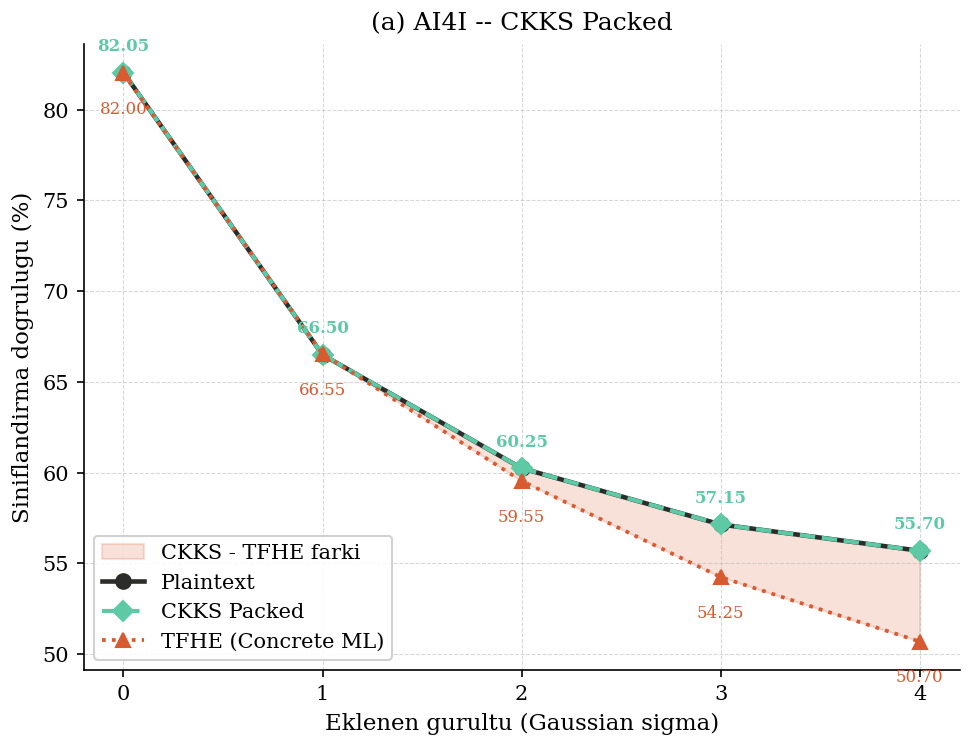

  -> figure3a_ai4i_packed.png + .pdf kaydedildi.


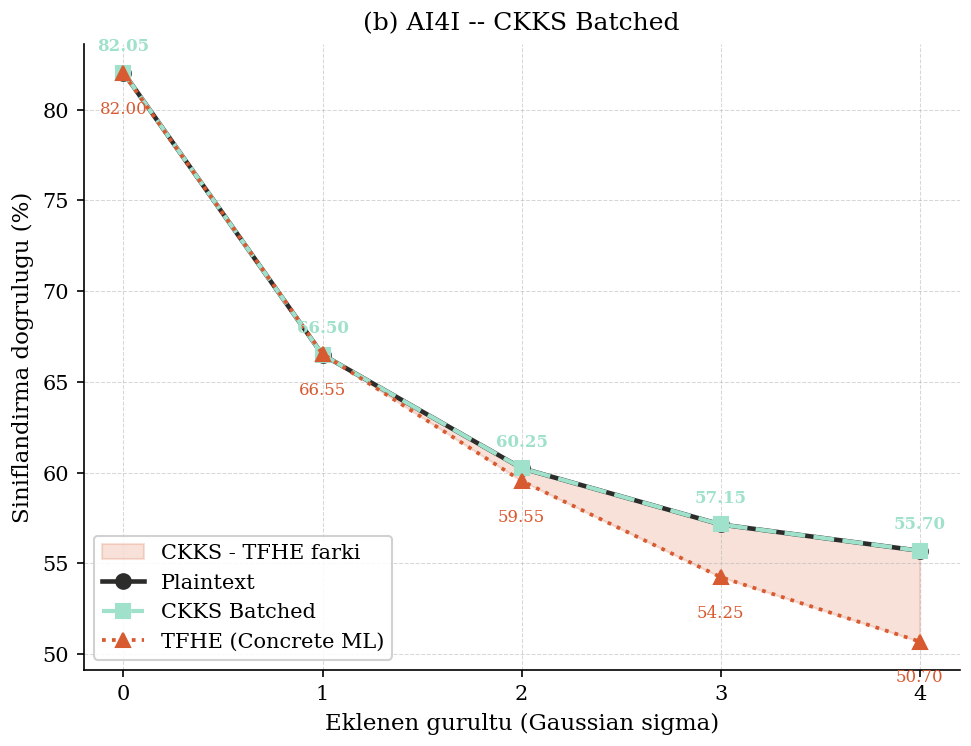

  -> figure3b_ai4i_batched.png + .pdf kaydedildi.


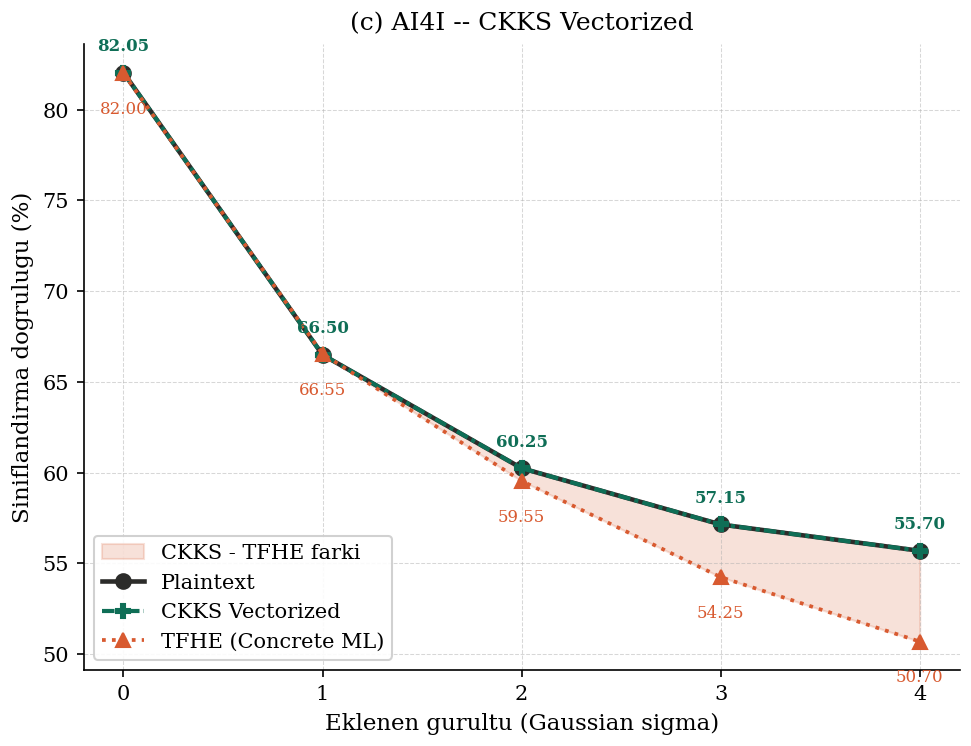

  -> figure3c_ai4i_vectorized.png + .pdf kaydedildi.


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

STYLE = {
    "font.family": "serif", "font.size": 11, "axes.titlesize": 12,
    "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "legend.fontsize": 10, "legend.framealpha": 0.9, "legend.edgecolor": "#CCCCCC",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.linestyle": "--", "grid.linewidth": 0.5, "grid.alpha": 0.5,
    "figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.08,
}
C_PLAIN, C_CKKS_P, C_CKKS_VEC, C_TFHE = "#2C2C2A", "#5DCAA5", "#0F6E56", "#D85A30"

def save_fig(name):
    path = os.path.join(SAVE_DIR, f"{name}.png")
    plt.savefig(path)
    plt.savefig(os.path.join(SAVE_DIR, f"{name}.pdf"))
    plt.show()
    print(f"  -> {name}.png + .pdf kaydedildi.")

# --- AI4I icin tum CKKS modlarinda (Packed/Batched/Vectorized) gurultu stres testi ---
noise_levels_ai4i = [0.0, 1.0, 2.0, 3.0, 4.0]
acc_plain, acc_packed, acc_batched, acc_vec, acc_tfhe = [], [], [], [], []

for sigma in noise_levels_ai4i:
    np.random.seed(42)
    Xn = X_test_ai4i + np.random.normal(0, sigma, X_test_ai4i.shape)

    acc_plain.append(accuracy_score(y_test_ai4i, clf_ai4i.predict(Xn)) * 100)

    p_packed = []
    for i in range(0, len(Xn), 100):
        dec = fhe_predict_packed(ctx_ai4i, Xn[i:i+100], w_ai4i, b_ai4i)
        p_packed.extend([1 if v > 0.5 else 0 for v in dec])
    acc_packed.append(accuracy_score(y_test_ai4i, p_packed) * 100)

    p_batched, _ = fhe_predict_batched(ctx_ai4i, Xn, w_ai4i, b_ai4i, batch_size=100)
    acc_batched.append(accuracy_score(y_test_ai4i, p_batched) * 100)

    p_vec, _ = fhe_predict_vectorized(ctx_ai4i, Xn, w_ai4i, b_ai4i, batch_size=100)
    acc_vec.append(accuracy_score(y_test_ai4i, p_vec) * 100)

    acc_tfhe.append(accuracy_score(y_test_ai4i, concrete_ai4i.predict(Xn)) * 100)

    print(f"sigma={sigma:.1f}  Plain={acc_plain[-1]:.2f}%  Packed={acc_packed[-1]:.2f}%  "
          f"Batched={acc_batched[-1]:.2f}%  Vec={acc_vec[-1]:.2f}%  TFHE={acc_tfhe[-1]:.2f}%")


panels = [
    ("(a) AI4I -- CKKS Packed",     acc_packed,  C_CKKS_P,   "D", "--",          "figure3a_ai4i_packed"),
    ("(b) AI4I -- CKKS Batched",    acc_batched, "#9FE1CB",  "s", (0,(5,2)),     "figure3b_ai4i_batched"),
    ("(c) AI4I -- CKKS Vectorized", acc_vec,     C_CKKS_VEC, "P", (0,(3,1,1,1)), "figure3c_ai4i_vectorized"),
]

for title, acc_ckks, color, mkr, ls, fname in panels:
    with plt.style.context(STYLE):
        fig, ax = plt.subplots(figsize=(6.5, 5.0))
        ax.fill_between(noise_levels_ai4i, acc_ckks, acc_tfhe, alpha=0.18, color=C_TFHE, label="CKKS - TFHE farki")
        ax.plot(noise_levels_ai4i, acc_plain, color=C_PLAIN, lw=2.2, marker="o", ms=7, label="Plaintext")
        ax.plot(noise_levels_ai4i, acc_ckks, color=color, lw=2.0, ls=ls, marker=mkr, ms=7, label=title.split("--")[1].strip())
        ax.plot(noise_levels_ai4i, acc_tfhe, color=C_TFHE, lw=1.8, ls=":", marker="^", ms=7, label="TFHE (Concrete ML)")

        for x, yc, yt in zip(noise_levels_ai4i, acc_ckks, acc_tfhe):
            ax.text(x, yc + 1.0, f"{yc:.2f}", ha="center", va="bottom", fontsize=8, color=color, fontweight="bold")
            ax.text(x, yt - 1.5, f"{yt:.2f}", ha="center", va="top", fontsize=8, color=C_TFHE)

        ax.set_title(title, pad=7)
        ax.set_xlabel("Eklenen gurultu (Gaussian sigma)")
        ax.set_ylabel("Siniflandirma dogrulugu (%)")
        ax.set_xticks(noise_levels_ai4i)
        ax.legend(loc="lower left", frameon=True)
        plt.tight_layout(pad=0.6)
        save_fig(fname)

In [ ]:
def taylor_coeffs(degree):
    all_c = {0: 0.5, 1: 0.25, 3: -1/48, 5: 1/480}
    return {k: v for k, v in all_c.items() if k <= degree}

CHEBYSHEV_DOMAIN = (-13, 13)  

def chebyshev_coeffs(degree, domain=CHEBYSHEV_DOMAIN, n_points=8001):
    z = np.linspace(domain[0], domain[1], n_points)
    y = 1 / (1 + np.exp(-z))
    cheb = np.polynomial.chebyshev.Chebyshev.fit(z, y, degree, domain=domain)
    power = cheb.convert(kind=np.polynomial.Polynomial)
    return {i: float(c) for i, c in enumerate(power.coef) if abs(c) > 1e-10}

def poly_eval(z, coeffs):
    out = np.zeros_like(z, dtype=float)
    for p, c in coeffs.items():
        out += c * (z ** p)
    return out

APPROX_FAMILY = {
    "Taylor-1": taylor_coeffs(1), "Taylor-3": taylor_coeffs(3), "Taylor-5": taylor_coeffs(5),
    "Chebyshev-1": chebyshev_coeffs(1), "Chebyshev-3": chebyshev_coeffs(3), "Chebyshev-5": chebyshev_coeffs(5),
}
for name, c in APPROX_FAMILY.items():
    print(name, {k: round(v, 6) for k, v in c.items()})

Taylor-1 {0: 0.5, 1: 0.25}
Taylor-3 {0: 0.5, 1: 0.25, 3: -0.020833}
Taylor-5 {0: 0.5, 1: 0.25, 3: -0.020833, 5: 0.002083}
Chebyshev-1 {0: 0.5, 1: 0.056562}
Chebyshev-3 {0: 0.5, 1: 0.101544, 3: -0.000443}
Chebyshev-5 {0: 0.5, 1: 0.139101, 3: -0.00148, 5: 6e-06}


In [ ]:
if 'true_sigma_ai4i' not in dir():
    true_sigma_ai4i = 1 / (1 + np.exp(-plain_logits_ai4i))

rows = []
for name, coeffs in APPROX_FAMILY.items():
    approx = poly_eval(plain_logits_ai4i, coeffs)
    out_of_range = np.mean((approx < 0) | (approx > 1)) * 100
    mae = np.mean(np.abs(approx - true_sigma_ai4i))
    maxdev = np.max(np.abs(approx - true_sigma_ai4i))
    decisions_match = np.mean((approx > 0.5) == (plain_logits_ai4i > 0)) * 100
    rows.append({"Yontem": name, "[0,1] Disi (%)": round(out_of_range, 1),
                 "MAE": round(mae, 4), "Maks. Sapma": round(maxdev, 4),
                 "Karar Uyumu (%)": round(decisions_match, 2)})

df_calibration = pd.DataFrame(rows)
print(df_calibration.to_string(index=False))

     Yontem  [0,1] Disi (%)    MAE  Maks. Sapma  Karar Uyumu (%)
   Taylor-1            45.1 0.1698       1.1001           100.00
   Taylor-3             5.5 0.2074       4.3454            85.05
   Taylor-5            33.8 0.3421      17.9161           100.00
Chebyshev-1             0.0 0.2075       0.2844           100.00
Chebyshev-3             0.0 0.1278       0.1818           100.00
Chebyshev-5             3.4 0.0740       0.1164           100.00


In [ ]:
def make_ckks_context_depth(mult_depth, poly_modulus_degree=16384, scale_bits=40):
    coeff_mod_bit_sizes = [60] + [scale_bits] * mult_depth + [60]
    context = ts.context(ts.SCHEME_TYPE.CKKS, poly_modulus_degree=poly_modulus_degree,
                          coeff_mod_bit_sizes=coeff_mod_bit_sizes)
    context.global_scale = 2 ** scale_bits
    context.generate_galois_keys()
    return context


ctx_depth3 = make_ckks_context_depth(mult_depth=3, poly_modulus_degree=16384)

ctx_depth5 = make_ckks_context_depth(mult_depth=5, poly_modulus_degree=16384)
print("Contextler hazir.")

Contextler hazir.


In [ ]:
def sigmoid_poly_encrypted(enc_z, coeffs):
    powers = {1: enc_z}
    max_p = max([k for k in coeffs if k > 1], default=1)
    cur = enc_z
    for p in range(2, max_p + 1):
        cur = cur * enc_z          
        powers[p] = cur
    const = coeffs.get(0, 0.0)
    result = None
    for power, c in coeffs.items():
        if power == 0:
            continue
        term = powers[power] * c
        result = term if result is None else result + term
    return result + const

def fhe_predict_poly_batch(context, X_batch, w, b, coeffs):
    X_batch = np.array(X_batch)
    features = X_batch.T
    vecs = [ts.ckks_vector(context, feat.tolist()) for feat in features]
    z = vecs[0] * w[0]
    for i in range(1, len(vecs)):
        z += vecs[i] * w[i]
    z = z + b
    sigma = sigmoid_poly_encrypted(z, coeffs)
    out = sigma.decrypt()
    return [1 if v > 0.5 else 0 for v in out]

In [ ]:
def make_ckks_context_depth(mult_depth, poly_modulus_degree=16384, scale_bits=40):
    coeff_mod_bit_sizes = [60] + [scale_bits] * mult_depth + [60]
    context = ts.context(ts.SCHEME_TYPE.CKKS, poly_modulus_degree=poly_modulus_degree,
                          coeff_mod_bit_sizes=coeff_mod_bit_sizes)
    context.global_scale = 2 ** scale_bits
    context.generate_galois_keys()
    return context

ctx_depth3 = make_ckks_context_depth(mult_depth=5, poly_modulus_degree=16384)

ctx_depth5 = make_ckks_context_depth(mult_depth=8, poly_modulus_degree=32768)

print("Contextler (duzeltilmis derinlikle) hazir.")

Contextler (duzeltilmis derinlikle) hazir.


In [17]:
POLY_CONTEXTS = {
    "Taylor-1": ctx_ai4i, "Chebyshev-1": ctx_ai4i,
    "Taylor-3": ctx_depth3, "Chebyshev-3": ctx_depth3,
    "Taylor-5": ctx_depth5, "Chebyshev-5": ctx_depth5,
}

ablation_rows = []
for name, coeffs in APPROX_FAMILY.items():
    ctx = POLY_CONTEXTS[name]
    t0 = time.perf_counter()
    preds = []
    for i in range(0, len(X_test_ai4i), 100):
        preds.extend(fhe_predict_poly_batch(ctx, X_test_ai4i[i:i+100], w_ai4i, b_ai4i, coeffs))
    elapsed = time.perf_counter() - t0
    acc = accuracy_score(y_test_ai4i, preds)
    agree = np.mean(np.array(preds) == (clf_ai4i.predict(X_test_ai4i)))
    max_power = max([k for k in coeffs if k > 1], default=1)
    ablation_rows.append({"Yontem": name, "Derinlik": max_power - 1 if max_power > 1 else 0,
                           "Dogruluk (%)": round(acc*100, 2), "Sure (s)": round(elapsed, 3),
                           "Plaintext Uyumu (%)": round(agree*100, 2)})

df_ablation = pd.DataFrame(ablation_rows)
print(df_ablation.to_string(index=False))

     Yontem  Derinlik  Dogruluk (%)  Sure (s)  Plaintext Uyumu (%)
   Taylor-1         0         82.05     0.652               100.00
   Taylor-3         2         67.40     2.786                85.05
   Taylor-5         4         82.05    10.412               100.00
Chebyshev-1         0         82.05     0.651               100.00
Chebyshev-3         2         82.05     2.787               100.00
Chebyshev-5         4         82.05    10.368               100.00


In [ ]:
tfhe_proba_ai4i = concrete_ai4i.predict_proba(X_test_ai4i)[:, 1]

out_of_range_tfhe = np.mean((tfhe_proba_ai4i < 0) | (tfhe_proba_ai4i > 1)) * 100
mae_tfhe = np.mean(np.abs(tfhe_proba_ai4i - true_sigma_ai4i))
maxdev_tfhe = np.max(np.abs(tfhe_proba_ai4i - true_sigma_ai4i))

print(f"TFHE  [0,1] Disi: %{out_of_range_tfhe:.1f}   MAE: {mae_tfhe:.4f}   Maks. Sapma: {maxdev_tfhe:.4f}")


TFHE  [0,1] Disi: %0.0   MAE: 0.0049   Maks. Sapma: 0.0291


In [ ]:
approx_sigma_ai4i = sigmoid_deg1(plain_logits_ai4i)

print(f"z (logit) araligi:        min={plain_logits_ai4i.min():.3f}  max={plain_logits_ai4i.max():.3f}")
print(f"Yaklasik sigma araligi:    min={approx_sigma_ai4i.min():.3f}  max={approx_sigma_ai4i.max():.3f}")

out_of_range = np.sum((approx_sigma_ai4i < 0) | (approx_sigma_ai4i > 1))
print(f"[0,1] disina cikan ornek sayisi: {out_of_range} / {len(approx_sigma_ai4i)}  ({out_of_range/len(approx_sigma_ai4i)*100:.1f}%)")

true_sigma_ai4i = 1 / (1 + np.exp(-plain_logits_ai4i))
calibration_error = np.abs(approx_sigma_ai4i - true_sigma_ai4i)
print(f"Ortalama kalibrasyon hatasi |yaklasik - gercek|: {calibration_error.mean():.3f}")
print(f"Maksimum kalibrasyon hatasi: {calibration_error.max():.3f}")

z (logit) araligi:        min=-6.394  max=5.649
Yaklasik sigma araligi:    min=-1.098  max=1.912
[0,1] disina cikan ornek sayisi: 902 / 2000  (45.1%)
Ortalama kalibrasyon hatasi |yaklasik - gercek|: 0.170
Maksimum kalibrasyon hatasi: 1.100


## Case Study II: CWRU Bearing Dataset

In [ ]:
def download_file_with_backup(filename, url_list):
    if os.path.exists(filename):
        print(f"{filename} zaten diskte mevcut, indirme atlaniyor.")
        return True
    for url in url_list:
        try:
            headers = {'User-Agent': 'Mozilla/5.0'}
            response = requests.get(url, headers=headers, allow_redirects=True, timeout=10)
            if response.status_code == 200:
                with open(filename, 'wb') as f:
                    f.write(response.content)
                print(f"Indirildi: {filename} <- {url}")
                return True
        except Exception as e:
            print(f"Hata ({url}): {e}, siradaki kaynaga geciliyor...")
    print(f"KRITIK HATA: {filename} hicbir kaynaktan indirilemedi.")
    return False


CWRU_URLS = {
    '97.mat': [
        'https://raw.githubusercontent.com/BillWangUp/CWRU-1/master/Data/Normal_0_load/97.mat',
        'https://raw.githubusercontent.com/jkwd/CWRU-1/master/Data/Normal_0_load/97.mat',
        'https://engineering.case.edu/sites/default/files/97.mat',
    ],
    '105.mat': [
        'https://raw.githubusercontent.com/BillWangUp/CWRU-1/master/Data/12k_Drive_End_B007_0_load/105.mat',
        'https://raw.githubusercontent.com/jkwd/CWRU-1/master/Data/12k_Drive_End_B007_0_load/105.mat',
        'https://engineering.case.edu/sites/default/files/105.mat',
    ],
}

for name, links in CWRU_URLS.items():
    download_file_with_backup(name, links)


def load_de_signal(mat_path):
    mat = scipy.io.loadmat(mat_path)
    key = [k for k in mat.keys() if 'DE_time' in k][0]
    return mat[key].flatten()


def extract_windows(signal, label, window_size=1024, stride=1024):
    """stride == window_size -> orintusmesiz (test icin); stride < window_size -> ortusmeli (train icin)."""
    rows = []
    n_windows = (len(signal) - window_size) // stride + 1
    for i in range(n_windows):
        start = i * stride
        seg = signal[start:start + window_size]
        rms = np.sqrt(np.mean(seg ** 2))
        rows.append([
            rms,
            kurtosis(seg),
            np.max(np.abs(seg)),
            (np.max(np.abs(seg)) / rms) if rms != 0 else 0.0,
            skew(seg),
            label,
        ])
    return pd.DataFrame(rows, columns=["RMS", "Kurtosis", "Peak", "CrestFactor", "Skewness", "Label"])


def split_then_window(signal, label, test_fraction=0.2, window_size=1024, train_stride=256):
    """Once zaman ekseninde bol (sizinti yok), sonra ayri ayri pencerele."""
    split_idx = int(len(signal) * (1 - test_fraction))
    train_signal, test_signal = signal[:split_idx], signal[split_idx:]
    train_df = extract_windows(train_signal, label, window_size, stride=train_stride)   # ortusmeli (augmentation)
    test_df = extract_windows(test_signal, label, window_size, stride=window_size)      # ortusmesiz (dogru degerlendirme)
    return train_df, test_df


signal_healthy = load_de_signal('97.mat')
signal_faulty = load_de_signal('105.mat')

train_h, test_h = split_then_window(signal_healthy, label=0)
train_f, test_f = split_then_window(signal_faulty, label=1)

train_df_cwru = pd.concat([train_h, train_f]).sample(frac=1, random_state=RNG_SEED).reset_index(drop=True)
test_df_cwru = pd.concat([test_h, test_f]).sample(frac=1, random_state=RNG_SEED).reset_index(drop=True)

X_train_raw = train_df_cwru.drop('Label', axis=1).values
y_train_cwru = train_df_cwru['Label'].values
X_test_raw = test_df_cwru.drop('Label', axis=1).values
y_test_cwru = test_df_cwru['Label'].values

scaler_cwru = StandardScaler()
X_train_cwru = scaler_cwru.fit_transform(X_train_raw)
X_test_cwru_clean = scaler_cwru.transform(X_test_raw)

print(f"Train: {X_train_cwru.shape}  (ortusmeli, artirilmis)")
print(f"Test:  {X_test_cwru_clean.shape}  (ortusmesiz, bagimsiz)")


97.mat zaten diskte mevcut, indirme atlaniyor.
105.mat zaten diskte mevcut, indirme atlaniyor.
Train: (1134, 5)  (ortusmeli, artirilmis)
Test:  (70, 5)  (ortusmesiz, bagimsiz)


In [ ]:
NOISE_SIGMA = 0.5
np.random.seed(99)
X_test_cwru = X_test_cwru_clean + np.random.normal(0, NOISE_SIGMA, X_test_cwru_clean.shape)

clf_cwru = LogisticRegression(max_iter=1000, class_weight='balanced')
clf_cwru.fit(X_train_cwru, y_train_cwru)
w_cwru, b_cwru = clf_cwru.coef_[0], clf_cwru.intercept_[0]

concrete_cwru = ConcreteLogisticRegression(n_bits=8, class_weight='balanced')
concrete_cwru.fit(X_train_cwru, y_train_cwru)
_ = concrete_cwru.compile(X_train_cwru)

ctx_cwru = make_ckks_context()
print("CWRU modeli ve CKKS baglami hazir.")


CWRU modeli ve CKKS baglami hazir.


In [22]:
res_cwru, preds_cwru = run_all_inference_modes(
    ctx_cwru, clf_cwru, concrete_cwru, X_test_cwru, y_test_cwru, w_cwru, b_cwru, batch_size=100
)
df_res_cwru = summarize_results(res_cwru)
print(df_res_cwru.to_string(index=False))


            Mod  Dogruluk (%)  Sure (s)  Precision  Recall  F1  AUC
          Plain         100.0    0.0004        1.0     1.0 1.0  1.0
    CKKS-Single         100.0    0.7808        1.0     1.0 1.0  NaN
    CKKS-Packed         100.0    0.0276        1.0     1.0 1.0  NaN
   CKKS-Batched         100.0    0.0273        1.0     1.0 1.0  NaN
CKKS-Vectorized         100.0    0.0278        1.0     1.0 1.0  NaN
TFHE-ConcreteML         100.0    0.0002        1.0     1.0 1.0  NaN


In [23]:
plain_logits_cwru = clf_cwru.decision_function(X_test_cwru)
approx_sigma_cwru = sigmoid_deg1(plain_logits_cwru)

print(f"z (logit) araligi:        min={plain_logits_cwru.min():.3f}  max={plain_logits_cwru.max():.3f}")
print(f"Yaklasik sigma araligi:    min={approx_sigma_cwru.min():.3f}  max={approx_sigma_cwru.max():.3f}")

out_of_range_cwru = np.sum((approx_sigma_cwru < 0) | (approx_sigma_cwru > 1))
print(f"[0,1] disina cikan ornek sayisi: {out_of_range_cwru} / {len(approx_sigma_cwru)}")

z (logit) araligi:        min=-10.779  max=12.263
Yaklasik sigma araligi:    min=-2.195  max=3.566
[0,1] disina cikan ornek sayisi: 70 / 70


In [ ]:
plain_logits_cwru = clf_cwru.decision_function(X_test_cwru)
true_sigma_cwru = 1 / (1 + np.exp(-plain_logits_cwru))

rows_cwru = []
for name, coeffs in APPROX_FAMILY.items():
    approx = poly_eval(plain_logits_cwru, coeffs)
    out_of_range = np.mean((approx < 0) | (approx > 1)) * 100
    mae = np.mean(np.abs(approx - true_sigma_cwru))
    maxdev = np.max(np.abs(approx - true_sigma_cwru))
    decisions_match = np.mean((approx > 0.5) == (plain_logits_cwru > 0)) * 100
    rows_cwru.append({"Yontem": name, "[0,1] Disi (%)": round(out_of_range, 1),
                       "MAE": round(mae, 4), "Maks. Sapma": round(maxdev, 4),
                       "Karar Uyumu (%)": round(decisions_match, 2)})
print(pd.DataFrame(rows_cwru).to_string(index=False))

ablation_rows_cwru = []
for name, coeffs in APPROX_FAMILY.items():
    ctx = POLY_CONTEXTS[name]
    t0 = time.perf_counter()
    preds = fhe_predict_poly_batch(ctx, X_test_cwru, w_cwru, b_cwru, coeffs)
    elapsed = time.perf_counter() - t0
    acc = accuracy_score(y_test_cwru, preds)
    agree = np.mean(np.array(preds) == clf_cwru.predict(X_test_cwru))
    ablation_rows_cwru.append({"Yontem": name, "Dogruluk (%)": round(acc*100, 2),
                                "Sure (s)": round(elapsed, 4), "Plaintext Uyumu (%)": round(agree*100, 2)})
print(pd.DataFrame(ablation_rows_cwru).to_string(index=False))


     Yontem  [0,1] Disi (%)     MAE  Maks. Sapma  Karar Uyumu (%)
   Taylor-1           100.0  1.1895       2.5658           100.00
   Taylor-3            90.0  6.8037      35.8565             5.71
   Taylor-5           100.0 49.9329     541.9733           100.00
Chebyshev-1            14.3  0.1266       0.2843           100.00
Chebyshev-3            67.1  0.0675       0.1758           100.00
Chebyshev-5            77.1  0.0402       0.0964           100.00
     Yontem  Dogruluk (%)  Sure (s)  Plaintext Uyumu (%)
   Taylor-1        100.00    0.0282               100.00
   Taylor-3          5.71    0.1237                 5.71
   Taylor-5        100.00    0.4734               100.00
Chebyshev-1        100.00    0.0282               100.00
Chebyshev-3        100.00    0.1230               100.00
Chebyshev-5        100.00    0.4696               100.00


In [ ]:
noise_levels = [0.0, 1.0, 2.0, 3.0, 4.0]
stress_rows = []

for sigma in noise_levels:
    np.random.seed(42)
    X_noisy = X_test_cwru_clean + np.random.normal(0, sigma, X_test_cwru_clean.shape)

    y_pred_plain = clf_cwru.predict(X_noisy)
    acc_plain = accuracy_score(y_test_cwru, y_pred_plain)

    y_pred_ckks = []
    for i in range(0, len(X_noisy), 100):
        decrypted = fhe_predict_packed(ctx_cwru, X_noisy[i:i + 100], w_cwru, b_cwru)
        y_pred_ckks.extend([1 if v > 0.5 else 0 for v in decrypted])
    acc_ckks = accuracy_score(y_test_cwru, y_pred_ckks)

    try:
        y_pred_tfhe = concrete_cwru.predict(X_noisy)
        acc_tfhe = accuracy_score(y_test_cwru, y_pred_tfhe)
    except Exception:
        acc_tfhe = float("nan")

    stress_rows.append({"Sigma": sigma, "Plain (%)": acc_plain * 100,
                         "CKKS-Vectorized (%)": acc_ckks * 100, "TFHE (%)": acc_tfhe * 100})

df_stress = pd.DataFrame(stress_rows)
print(df_stress.to_string(index=False))


 Sigma  Plain (%)  CKKS-Vectorized (%)   TFHE (%)
   0.0 100.000000           100.000000 100.000000
   1.0  98.571429            98.571429  98.571429
   2.0  87.142857            87.142857  88.571429
   3.0  81.428571            81.428571  81.428571
   4.0  74.285714            74.285714  71.428571


In [26]:
noise_levels = [0.0, 1.0, 2.0, 3.0, 4.0]
acc_plain, acc_packed, acc_batched, acc_vec, acc_tfhe = [], [], [], [], []

for sigma in noise_levels:
    np.random.seed(42)
    X_noisy = X_test_cwru_clean + np.random.normal(0, sigma, X_test_cwru_clean.shape)

    acc_plain.append(accuracy_score(y_test_cwru, clf_cwru.predict(X_noisy)) * 100)

    p_packed = []
    for i in range(0, len(X_noisy), 100):
        dec = fhe_predict_packed(ctx_cwru, X_noisy[i:i+100], w_cwru, b_cwru)
        p_packed.extend([1 if v > 0.5 else 0 for v in dec])
    acc_packed.append(accuracy_score(y_test_cwru, p_packed) * 100)

    p_batched, _ = fhe_predict_batched(ctx_cwru, X_noisy, w_cwru, b_cwru, batch_size=100)
    acc_batched.append(accuracy_score(y_test_cwru, p_batched) * 100)

    p_vec, _ = fhe_predict_vectorized(ctx_cwru, X_noisy, w_cwru, b_cwru, batch_size=100)
    acc_vec.append(accuracy_score(y_test_cwru, p_vec) * 100)

    try:
        acc_tfhe.append(accuracy_score(y_test_cwru, concrete_cwru.predict(X_noisy)) * 100)
    except Exception:
        acc_tfhe.append(float("nan"))

    print(f"sigma={sigma:.1f}  Plain={acc_plain[-1]:.2f}%  Packed={acc_packed[-1]:.2f}%  "
          f"Batched={acc_batched[-1]:.2f}%  Vec={acc_vec[-1]:.2f}%  TFHE={acc_tfhe[-1]:.2f}%")

df_stress = pd.DataFrame({"Sigma": noise_levels, "Plain (%)": acc_plain,
                          "CKKS-Vectorized (%)": acc_vec, "TFHE (%)": acc_tfhe})
print(df_stress.to_string(index=False))

sigma=0.0  Plain=100.00%  Packed=100.00%  Batched=100.00%  Vec=100.00%  TFHE=100.00%
sigma=1.0  Plain=98.57%  Packed=98.57%  Batched=98.57%  Vec=98.57%  TFHE=98.57%
sigma=2.0  Plain=87.14%  Packed=87.14%  Batched=87.14%  Vec=87.14%  TFHE=88.57%
sigma=3.0  Plain=81.43%  Packed=81.43%  Batched=81.43%  Vec=81.43%  TFHE=81.43%
sigma=4.0  Plain=74.29%  Packed=74.29%  Batched=74.29%  Vec=74.29%  TFHE=71.43%
 Sigma  Plain (%)  CKKS-Vectorized (%)   TFHE (%)
   0.0 100.000000           100.000000 100.000000
   1.0  98.571429            98.571429  98.571429
   2.0  87.142857            87.142857  88.571429
   3.0  81.428571            81.428571  81.428571
   4.0  74.285714            74.285714  71.428571


Kaydedildi: ./FHE_Figures/figure1_ai4i_latency.png


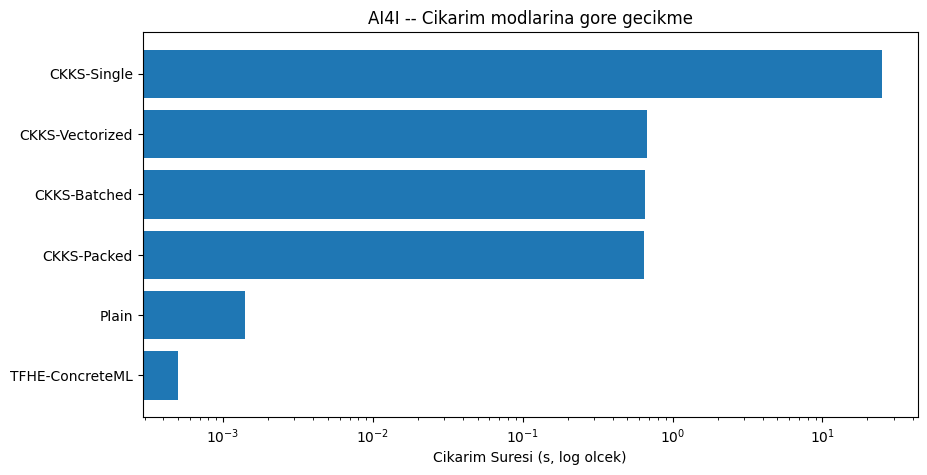

Kaydedildi: ./FHE_Figures/figure2_ai4i_noise_scatter.png


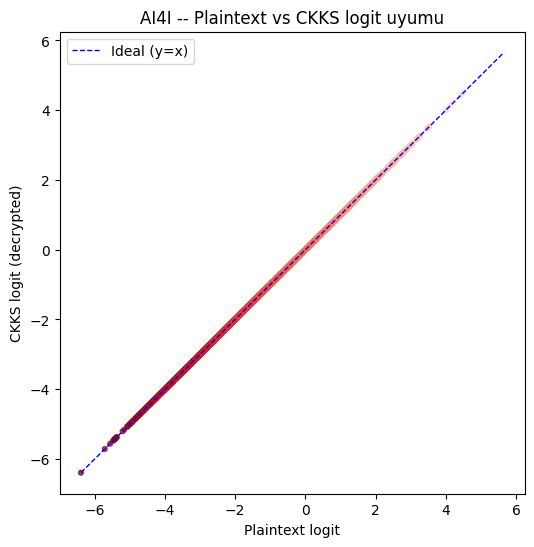

Kaydedildi: ./FHE_Figures/figure3_cwru_robustness.png


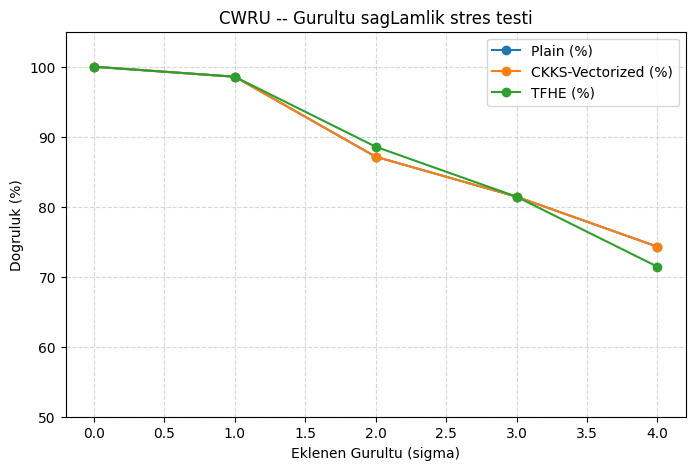

In [27]:
def save_and_show(fig, filename):
    path = os.path.join(SAVE_DIR, filename)
    fig.savefig(path, dpi=300, bbox_inches='tight')
    print(f"Kaydedildi: {path}")
    plt.show()


# Figure 1 -- gecikme karsilastirmasi (AI4I)
fig, ax = plt.subplots(figsize=(10, 5))
order = df_res_ai4i.sort_values("Sure (s)")
ax.barh(order["Mod"], order["Sure (s)"])
ax.set_xscale('log')
ax.set_xlabel("Cikarim Suresi (s, log olcek)")
ax.set_title("AI4I -- Cikarim modlarina gore gecikme")
save_and_show(fig, "figure1_ai4i_latency.png")

# Figure 2 -- gurultu sacilim grafigi (AI4I)
fig, ax = plt.subplots(figsize=(6, 6))
sc = ax.scatter(plain_logits_ai4i, ckks_logits_ai4i, c=noise_ai4i, cmap='Reds', s=12, alpha=0.7)
lims = [plain_logits_ai4i.min(), plain_logits_ai4i.max()]
ax.plot(lims, lims, 'b--', linewidth=1, label='Ideal (y=x)')
ax.set_xlabel("Plaintext logit")
ax.set_ylabel("CKKS logit (decrypted)")
ax.set_title("AI4I -- Plaintext vs CKKS logit uyumu")
ax.legend()
save_and_show(fig, "figure2_ai4i_noise_scatter.png")

# Figure 3 -- gurultu-saglamlik stres testi (CWRU)
fig, ax = plt.subplots(figsize=(8, 5))
for col in ["Plain (%)", "CKKS-Vectorized (%)", "TFHE (%)"]:
    ax.plot(df_stress["Sigma"], df_stress[col], marker='o', label=col)
ax.set_xlabel("Eklenen Gurultu (sigma)")
ax.set_ylabel("Dogruluk (%)")
ax.set_ylim(50, 105)
ax.set_title("CWRU -- Gurultu sagLamlik stres testi")
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)
save_and_show(fig, "figure3_cwru_robustness.png")


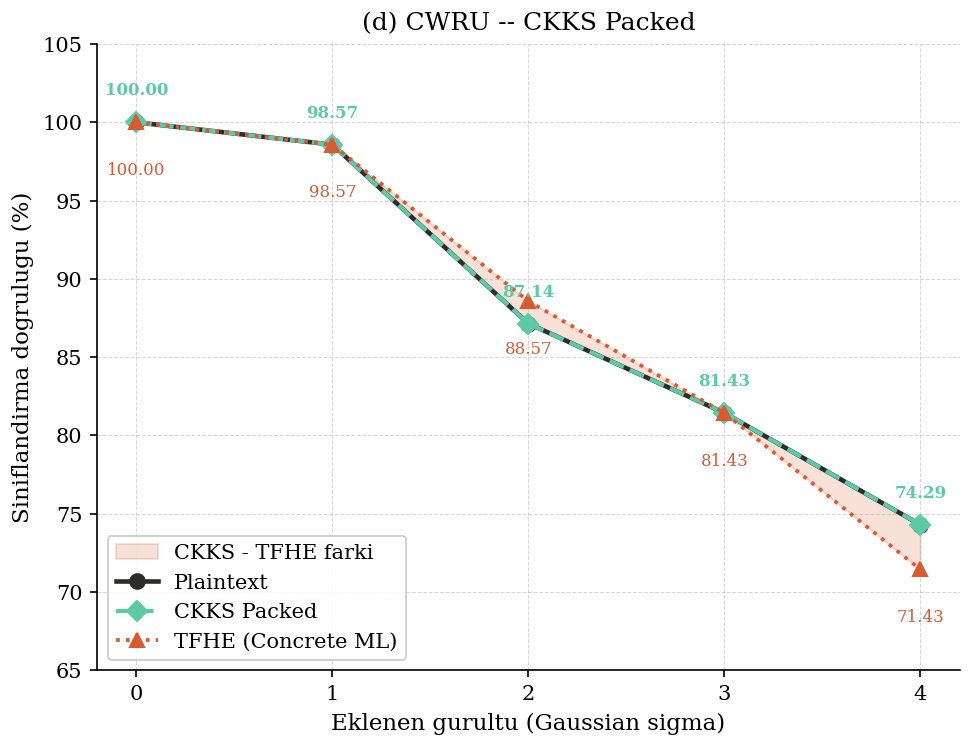

  -> figure3d_cwru_packed.png + .pdf kaydedildi.


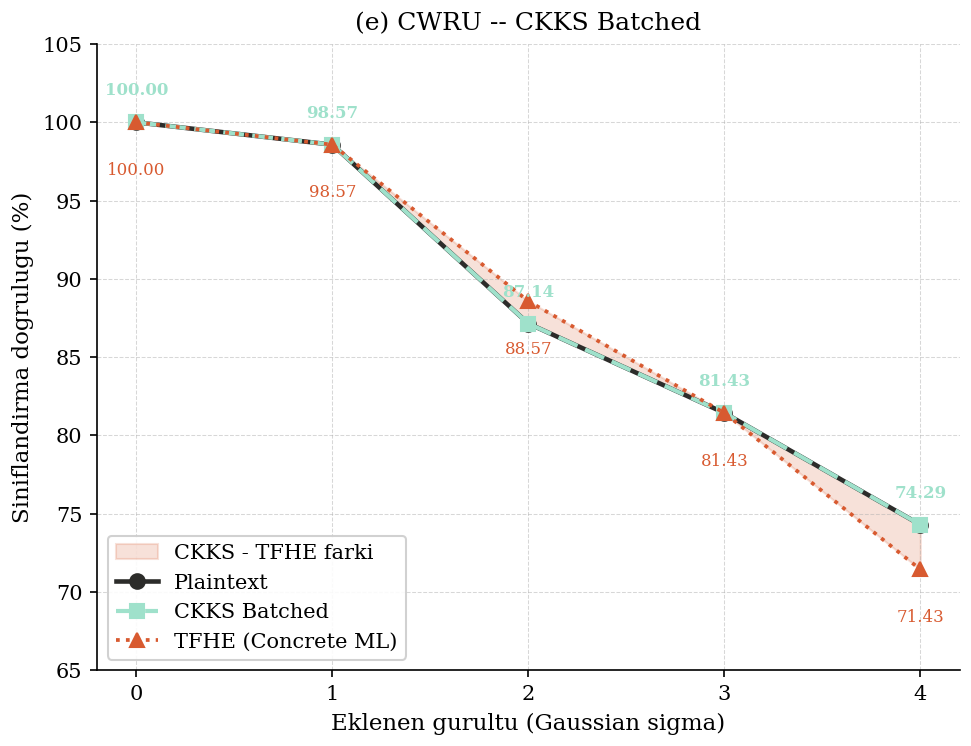

  -> figure3e_cwru_batched.png + .pdf kaydedildi.


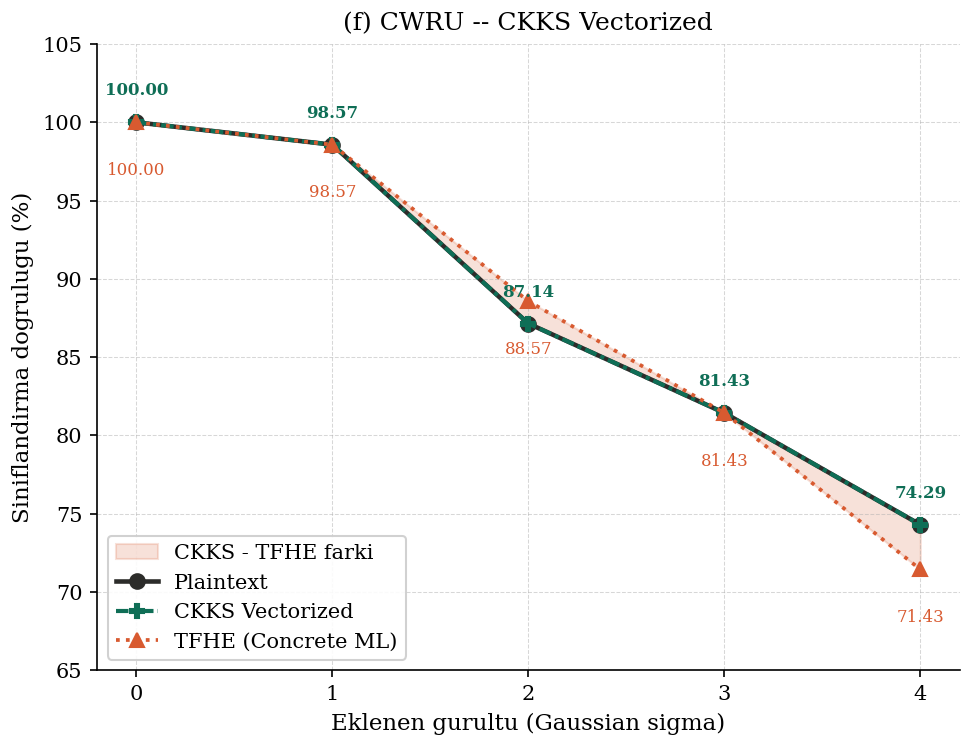

  -> figure3f_cwru_vectorized.png + .pdf kaydedildi.


In [28]:
# Figure 3(d,e,f): CWRU icin ayni panel stili, AI4I ile BIREBIR AYNI renk paleti
panels_cwru = [
    ("(d) CWRU -- CKKS Packed",     acc_packed,  C_CKKS_P,   "D", "--",          "figure3d_cwru_packed"),
    ("(e) CWRU -- CKKS Batched",    acc_batched, "#9FE1CB",  "s", (0,(5,2)),     "figure3e_cwru_batched"),
    ("(f) CWRU -- CKKS Vectorized", acc_vec,     C_CKKS_VEC, "P", (0,(3,1,1,1)), "figure3f_cwru_vectorized"),
]

for title, acc_ckks, color, mkr, ls, fname in panels_cwru:
    with plt.style.context(STYLE):
        fig, ax = plt.subplots(figsize=(6.5, 5.0))
        ax.fill_between(noise_levels, acc_ckks, acc_tfhe, alpha=0.18, color=C_TFHE, label="CKKS - TFHE farki")
        ax.plot(noise_levels, acc_plain, color=C_PLAIN, lw=2.2, marker="o", ms=7, label="Plaintext")
        ax.plot(noise_levels, acc_ckks, color=color, lw=2.0, ls=ls, marker=mkr, ms=7, label=title.split("--")[1].strip())
        ax.plot(noise_levels, acc_tfhe, color=C_TFHE, lw=1.8, ls=":", marker="^", ms=7, label="TFHE (Concrete ML)")

        for x, yc, yt in zip(noise_levels, acc_ckks, acc_tfhe):
            ax.text(x, yc + 1.5, f"{yc:.2f}", ha="center", va="bottom", fontsize=8, color=color, fontweight="bold")
            ax.text(x, yt - 2.5, f"{yt:.2f}", ha="center", va="top", fontsize=8, color=C_TFHE)

        ax.set_title(title, pad=7)
        ax.set_xlabel("Eklenen gurultu (Gaussian sigma)")
        ax.set_ylabel("Siniflandirma dogrulugu (%)")
        ax.set_xticks(noise_levels)
        ax.set_ylim(65, 105)
        ax.legend(loc="lower left", frameon=True)
        plt.tight_layout(pad=0.6)
        save_fig(fname)

In [ ]:
import platform, subprocess, sys

print("=" * 60)
print("DONANIM / YAZILIM ORTAMI")
print("=" * 60)

print(f"OS: {platform.system()} {platform.release()}")
try:
    with open('/etc/os-release') as f:
        for line in f:
            if line.startswith('PRETTY_NAME'):
                print(f"Dagitim: {line.split('=')[1].strip().strip(chr(34))}")
except Exception:
    pass

print(f"\nCPU mimarisi: {platform.machine()}")
try:
    cpuinfo = subprocess.run(['lscpu'], capture_output=True, text=True).stdout
    for line in cpuinfo.split('\n'):
        if any(k in line for k in ['Model name', 'Socket(s)', 'Core(s) per socket',
                                     'Thread(s) per core', 'CPU(s):', 'CPU max MHz', 'CPU min MHz']):
            print(line.strip())
except Exception as e:
    print("lscpu calismadi:", e)

# Bellek (RAM)
try:
    meminfo = subprocess.run(['free', '-h'], capture_output=True, text=True).stdout
    print(f"\n{meminfo}")
except Exception as e:
    print("free calismadi:", e)

# Python ve kutuphane surumleri
print(f"\nPython: {sys.version.split()[0]}")
for pkg in ["numpy", "pandas", "sklearn", "scipy", "tenseal", "torch", "concrete.ml", "matplotlib", "seaborn"]:
    try:
        mod = __import__(pkg)
        print(f"{pkg}: {mod.__version__}")
    except Exception:
        try:
            import importlib.metadata as m
            print(f"{pkg}: {m.version(pkg.split('.')[0])}")
        except Exception:
            print(f"{pkg}: bulunamadi")

print(f"\nHostname: {platform.node()}")

try:
    import torch
    print(f"CUDA mevcut mu: {torch.cuda.is_available()}")
except Exception:
    pass

DONANIM / YAZILIM ORTAMI
OS: Linux 5.14.0-284.30.1.el9_2.x86_64
Dagitim: Ubuntu 22.04.4 LTS

CPU mimarisi: x86_64
CPU(s):                          112
Model name:                      Intel(R) Xeon(R) Platinum 8480+
Thread(s) per core:              1
Core(s) per socket:              56
Socket(s):                       2
CPU max MHz:                     3800.0000
CPU min MHz:                     800.0000
NUMA node0 CPU(s):               0-13
NUMA node1 CPU(s):               14-27
NUMA node2 CPU(s):               28-41
NUMA node3 CPU(s):               42-55
NUMA node4 CPU(s):               56-69
NUMA node5 CPU(s):               70-83
NUMA node6 CPU(s):               84-97
NUMA node7 CPU(s):               98-111

               total        used        free      shared  buff/cache   available
Mem:           251Gi        15Gi       222Gi       508Mi        13Gi       233Gi
Swap:           31Gi       5.6Gi        26Gi


Python: 3.10.20
numpy: 1.26.4
pandas: 2.0.3
sklearn: 1.5.0
scipy: 1.15.